# Q5 — Is Buying a 2×16 GB Kit More Cost-Effective Than a Single 1×32 GB Stick?
**CSC17104 Final Project — DDR5 and NVMe Prices in 12 U.S. ZIP Markets (2026)**  
**Question Owner:** Đức Khải (Class 24C10)

---

## 1. Research Question & Motivation
- **Research Question:** Within the 32 GB total capacity tier of DDR5 memory, is it more cost-effective to purchase a single module (**1×32 GB**) or a dual-channel kit (**2×16 GB**) when evaluated on both total listing price (`price_amount` in USD) and normalized unit price (`normalized_price_amount` in USD/GB)? Does this price difference persist after controlling for hardware confounders (`form_factor`, `speed_mhz`, `brand`)?
- **Practical Motivation:** System builders and laptop upgraders face a fundamental economic and performance trade-off:
  1. Purchasing a 2×16 GB kit enables dual-channel memory architecture, optimizing memory bandwidth and processor throughput.
  2. Purchasing a single 1×32 GB stick may offer upfront cost savings and preserves an open memory slot for future capacity expansion.
- **Depth Criteria Addressed (Project Brief Section 3.3):**
  - **D3 (Derived variables):** Parsing `kit_config`, `form_factor` (UDIMM desktop vs. SODIMM laptop), `speed_mhz`, `cas_latency`, and `brand` from unstructured `product_name` strings via `src/parse_titles.py`.
  - **D4 (Controlling for confounders):** Analyzing how the crude price difference shifts under stratification by form factor and bus speed, as well as exact matching within identical brand cohorts (Apple-to-Apple comparisons).
  - **D5 (Quantifying uncertainty):** Estimating median price differences with 95% bootstrap confidence intervals (5,000 resamples) and Mann-Whitney U non-parametric hypothesis tests.
  - **D6 (Robustness / Sensitivity checks):** Evaluating conclusion stability against outlier exclusion rules (IQR 1.5×, IQR 3.0×, Z-score ≤ 3) and product-level median aggregation (`product_name` level).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual presentation styling
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False
})
sns.set_theme(style="whitegrid")

# Add repository root to sys.path (per src/io.py design rule to prevent shadowing stdlib io)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.io import load_raw
from src.cleaning import RowLog, add_flags, check_normalized_price
from src.parse_titles import add_parsed_features, audit_ddr5_parse_rate

# Initialize row count logger
log = RowLog()

# 1. Load raw dataset (10 agreed columns per DECISIONS.md) and attach quality flags
df_raw = load_raw(validate=True)
df = log.note(add_flags(df_raw), "add cleaning flags", reason="flag unresolved capacity & system noise without row deletion")

# 2. Extract structured technical attributes from product_name
df = log.note(add_parsed_features(df), "add parsed title features", reason="extract kit_config, form_factor, speed, brand for Q1/Q5/Q6")

print(f"Master dataset loaded: {len(df):,} rows | {df['product_name'].nunique():,} unique product titles.")

[OK] All 12 checks match the Kaggle data card.
[add cleaning flags] 127,843 -> 127,843 rows (removed 0)
[add parsed title features] 127,843 -> 127,843 rows (removed 0)
Master dataset loaded: 127,843 rows | 1,176 unique product titles.


## 2. Validation of Title Parsing (`src/parse_titles.py`)
In compliance with project risk mitigation guidelines (*"If product_name is parsed incorrectly, audit a sample of 100 titles and report the parse rate"*), the table below evaluates attribute extraction across all 221 genuine DDR5 products and specifically across the 91 products within the 32 GB target cohort.

In [2]:
# 1. Summary of parse success rates
audit_table = audit_ddr5_parse_rate(df)
print("=== TITLE PARSER AUDIT SUMMARY ===")
display(audit_table)

# 2. Audit random sample of 100 genuine DDR5 products to verify regex accuracy
pure_ddr5_unique = df[
    (df["series_id"] == "ddr5_memory") & 
    (~df["is_system_noise"]) & 
    (~df["is_nas_appliance"])
].drop_duplicates("product_name")

sample_100 = pure_ddr5_unique[[
    "product_name", "quantity_value", "brand", "kit_config", 
    "kit_parse_rule", "form_factor", "speed_mhz", "cas_latency"
]].sample(100, random_state=42)

print("\n=== AUDIT SAMPLE OF 100 DDR5 PRODUCTS (FIRST 10 ROWS DISPLAYED) ===")
display(sample_100.head(10))

=== TITLE PARSER AUDIT SUMMARY ===


,parsed_attribute,All Pure DDR5 (n=221 products),DDR5 32GB Q5 (n=91 products)
0,brand,221/221 (100.00%),91/91 (100.00%)
1,kit_config (2x16GB vs 1x32GB),221/221 (100.00%),91/91 (100.00%)
2,form_factor (UDIMM vs SODIMM),221/221 (100.00%),91/91 (100.00%)
3,speed_mhz,221/221 (100.00%),91/91 (100.00%)
4,cas_latency,216/221 (97.74%),90/91 (98.90%)



=== AUDIT SAMPLE OF 100 DDR5 PRODUCTS (FIRST 10 ROWS DISPLAYED) ===


,product_name,quantity_value,brand,kit_config,kit_parse_rule,form_factor,speed_mhz,cas_latency
1062,V-Color DDR5 256GB (64GBx4) 6400MHz CL60 ECC R...,256.0,V-COLOR,4x64GB,Explicit_MxN,UDIMM,6400.0,60.0
1482,G.SKILL Trident Z5 NeoX RGB Series DDR5 RAM (A...,32.0,G.SKILL,2x16GB,Explicit_NxM,UDIMM,6000.0,30.0
500,"Crucial 64GB DDR5 RAM, 5600MHz (or 5200MHz or ...",64.0,CRUCIAL,2x32GB,PartNum_Kit2,SODIMM,5600.0,46.0
4037,CORSAIR Vengeance DDR5 RAM 32GB (2x16GB) 6000M...,32.0,CORSAIR,2x16GB,Explicit_NxM,UDIMM,6000.0,30.0
15,CORSAIR Vengeance RGB DDR5 RAM 32GB (2x16GB) U...,32.0,CORSAIR,2x16GB,Explicit_NxM,UDIMM,6000.0,36.0
869,PNY DDR5 16GB (1x16GB) 5600MHz CL46 Performanc...,16.0,PNY,1x16GB,Explicit_NxM,UDIMM,5600.0,46.0
3052,DATO DDR5 UDIMM 32GB Kit 16GBx2 Desktop RAM 56...,32.0,DATO,2x16GB,Explicit_MxN,UDIMM,5600.0,46.0
13419,Acclamator DDR5 RAM 32GB 5600MHz (16GB×2) PC4-...,32.0,ACCLAMATOR,2x16GB,Explicit_MxN,UDIMM,5600.0,42.0
178,A-Tech 16GB DDR5 4800MHz PC5-38400 CL40 SODIMM...,16.0,A-TECH,1x16GB,Implicit_Single,SODIMM,4800.0,40.0
1360,CORSAIR Vengeance DDR5 SODIMM 32GB (2x16GB) Up...,32.0,CORSAIR,2x16GB,Explicit_NxM,SODIMM,5600.0,48.0


## 3. Preprocessing Workflow & Row Count Tracking (`RowLog`)
In accordance with project reporting standards (*"Report row count before and after every data-changing step; every excluded row must be justified"*), the following explicit filters are applied:
1. Retain DDR5 memory listings (`series_id == 'ddr5_memory'`).
2. Exclude category contamination: 17 complete computer system rows (laptops/mini-PCs with `is_system_noise == True`) and 11 network-attached storage (NAS) rows at 16 GB.
3. Restrict analysis to products with exactly 32 GB total capacity (`quantity_value == 32.0`).

In [3]:
# 1. Inspect the 7 non-RAM systems (28 rows) misclassified under DDR5 memory
noise_items = df[(df["series_id"] == "ddr5_memory") & (df["is_system_noise"] | df["is_nas_appliance"])]
print("=== SYSTEM-LEVEL CONTAMINANTS EXCLUDED FROM DDR5 RAM ===")
display(
    noise_items.groupby(["quantity_value", "is_system_noise", "is_nas_appliance", "product_name"], observed=True)
    .agg(n_rows=("price_amount", "count"), median_price=("price_amount", "median"))
    .reset_index()
)

# 2. Execute explicit filter pipeline logged with RowLog
q5_df = log.step(df, "filter series_id == 'ddr5_memory'", lambda d: d[d["series_id"] == "ddr5_memory"], reason="Q5 only studies DDR5 RAM")
q5_df = log.step(q5_df, "drop complete systems (17 PC/Mini-PC rows)", lambda d: d[~d["is_system_noise"]], reason="exclude laptops/mini-PCs (including CWWK 32GB Mini-PC)")
q5_df = log.step(q5_df, "drop NAS appliances (11 NAS rows)", lambda d: d[~d["is_nas_appliance"]], reason="exclude diskless NAS appliances with 16GB RAM")
q5_df = log.step(q5_df, "filter quantity_value == 32.0 (32 GB)", lambda d: d[d["quantity_value"] == 32.0].copy(), reason="Q5 fixes total capacity at 32 GB")

print("\n=== ROW COUNT LOG TABLE (CRITERIA COMPLIANCE) ===")
display(log.table())

# 3. Verify missing values and internal consistency on Q5 analysis dataset
print("\n=== MISSING VALUES IN Q5 DATASET (9,607 ROWS) ===")
missing_report = q5_df[[
    "price_amount", "normalized_price_amount", "kit_config", 
    "form_factor", "speed_mhz", "brand", "cas_latency"
]].isna().sum().to_frame("Missing Count")
display(missing_report)

# Cross-check that normalized_price_amount perfectly equals price_amount / 32
max_diff = (q5_df["normalized_price_amount"] - (q5_df["price_amount"] / 32.0)).abs().max()
print(f"Maximum absolute difference between normalized_price_amount and (price_amount / 32): {max_diff:.8f}")

=== SYSTEM-LEVEL CONTAMINANTS EXCLUDED FROM DDR5 RAM ===


,quantity_value,is_system_noise,is_nas_appliance,product_name,n_rows,median_price
0,0.0,True,False,"CWWK Firewall Mini PC Intel N Series N100,DDR5...",1,597.40
1,0.0,True,False,"Dell 15.6"" Touchscreen Laptop Computer, 16GB D...",2,899.99
2,0.0,True,False,"Dell Desktop Computers, Intel 20-Core i7-14700...",1,1439.99
3,0.0,True,False,"GEEKOM A8 Mini PC, Ryzen 7 8745HS, 16GB DDR5 U...",10,585.65
4,0.0,True,False,MINISFORUM DeskMini UM760 Slim Mini PC AMD Ryz...,3,535.90
5,16.0,False,True,"Asustor Lockerstor 10 Gen3 AS6810T 10 Bay NAS,...",3,2212.99
6,16.0,False,True,TERRAMASTER F8 SSD Plus NAS - 8Bay All SSD NAS...,8,899.99


[filter series_id == 'ddr5_memory'] 127,843 -> 18,650 rows (removed 109,193)
[drop complete systems (17 PC/Mini-PC rows)] 18,650 -> 18,633 rows (removed 17)
[drop NAS appliances (11 NAS rows)] 18,633 -> 18,622 rows (removed 11)
[filter quantity_value == 32.0 (32 GB)] 18,622 -> 9,607 rows (removed 9,015)

=== ROW COUNT LOG TABLE (CRITERIA COMPLIANCE) ===


,step,rows_before,rows_after,rows_removed,reason
0,add cleaning flags,127843,127843,0,flag unresolved capacity & system noise withou...
1,add parsed title features,127843,127843,0,"extract kit_config, form_factor, speed, brand ..."
2,filter series_id == 'ddr5_memory',127843,18650,109193,Q5 only studies DDR5 RAM
3,drop complete systems (17 PC/Mini-PC rows),18650,18633,17,exclude laptops/mini-PCs (including CWWK 32GB ...
4,drop NAS appliances (11 NAS rows),18633,18622,11,exclude diskless NAS appliances with 16GB RAM
5,filter quantity_value == 32.0 (32 GB),18622,9607,9015,Q5 fixes total capacity at 32 GB



=== MISSING VALUES IN Q5 DATASET (9,607 ROWS) ===


,Missing Count
price_amount,0
normalized_price_amount,0
kit_config,0
form_factor,0
speed_mhz,0
brand,0
cas_latency,84


Maximum absolute difference between normalized_price_amount and (price_amount / 32): 0.00000000


## 4. Exploratory Data Analysis: Crude Price Distribution (2×16 GB vs. 1×32 GB)
Direct comparison of unadjusted listed prices across all 9,607 observations in the 32 GB cohort. Both **Total Price (`price_amount` in USD)** and **Normalized Unit Price (`normalized_price_amount` in USD/GB)** are evaluated using non-parametric summary statistics (median and IQR) to account for heavy right-skewness.

In [4]:
# 1. Crude summary statistics by kit configuration
crude_summary = q5_df.groupby("kit_config", observed=True).agg(
    n_rows=("price_amount", "count"),
    n_products=("product_name", "nunique"),
    mean_price=("price_amount", "mean"),
    std_price=("price_amount", "std"),
    median_price=("price_amount", "median"),
    iqr_price=("price_amount", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    min_price=("price_amount", "min"),
    max_price=("price_amount", "max"),
    median_usd_gb=("normalized_price_amount", "median"),
    iqr_usd_gb=("normalized_price_amount", lambda s: s.quantile(0.75) - s.quantile(0.25)),
).round(2)

print("=== CRUDE SUMMARY STATISTICS: 2x16GB VS. 1x32GB ===")
display(crude_summary)

# 2. Exhaustive list of all 7 unique products comprising the 1x32GB group
print("\n=== COMPLETE BREAKDOWN OF ALL 7 UNIQUE PRODUCTS IN THE 1x32GB GROUP (589 ROWS) ===")
one_stick_products = (
    q5_df[q5_df["kit_config"] == "1x32GB"]
    .groupby(["brand", "form_factor", "speed_mhz", "cas_latency", "kit_parse_rule", "product_name"], observed=True)
    .agg(
        n_obs=("price_amount", "count"),
        median_price=("price_amount", "median"),
        median_usd_gb=("normalized_price_amount", "median")
    )
    .reset_index()
)
display(one_stick_products)

=== CRUDE SUMMARY STATISTICS: 2x16GB VS. 1x32GB ===


,n_rows,n_products,mean_price,std_price,median_price,iqr_price,min_price,max_price,median_usd_gb,iqr_usd_gb
kit_config,,,,,,,,,,
1x32GB,589,7,395.79,32.61,379.99,35.48,338.99,507.49,11.87,1.11
2x16GB,9018,84,489.67,79.35,469.99,55.00,349.99,1149.99,14.69,1.72



=== COMPLETE BREAKDOWN OF ALL 7 UNIQUE PRODUCTS IN THE 1x32GB GROUP (589 ROWS) ===


,brand,form_factor,speed_mhz,cas_latency,kit_parse_rule,product_name,n_obs,median_price,median_usd_gb
0,A-TECH,SODIMM,4800.0,40.0,Implicit_Single,A-Tech 32GB DDR5 4800MHz PC5-38400 CL40 SODIMM...,41,350.54,10.954375
1,A-TECH,UDIMM,4800.0,40.0,Implicit_Single,A-Tech 32GB DDR5 4800MHz PC5-38400 CL40 UDIMM ...,100,432.17,13.505313
2,CORSAIR,SODIMM,5600.0,48.0,Explicit_NxM,CORSAIR Vengeance SODIMM DDR5 RAM 32GB (1x32GB...,272,374.52,11.703750
3,CRUCIAL,SODIMM,5600.0,46.0,Implicit_Single,"Crucial 32GB DDR5 RAM, 5600MHz (or 5200MHz or ...",123,409.42,12.794375
4,KINGSTON,UDIMM,6000.0,36.0,Explicit_Single,Kingston FURY Beast 32GB 6000MT/s DDR5 CL36 RG...,17,389.99,12.187188
5,NEMIX,SODIMM,5600.0,46.0,Explicit_NxM,NEMIX RAM 32GB DDR5 5600MHz (1x32GB) SODIMM La...,24,459.00,14.343750
6,TIMETEC,SODIMM,5600.0,46.0,Implicit_Single,Timetec 32GB DDR5 5600MHz (PC5-5600) PC5-44800...,12,338.99,10.593438


## 5. Distribution Visualizations
In compliance with project visualization requirements (*"At least two well-labeled plots serving a specific analytical purpose, not just decoration"*):
- **Figure 1 (Left):** Grouped boxplot of total listed price (USD) by form factor (`UDIMM` vs. `SODIMM`) and kit configuration, illustrating price levels and high-end desktop overclocking outliers.
- **Figure 2 (Right):** Grouped boxplot of normalized unit price (USD/GB) across bus speed tiers (`speed_mhz`), illustrating unit price trends while suppressing extreme fliers to highlight median positions.

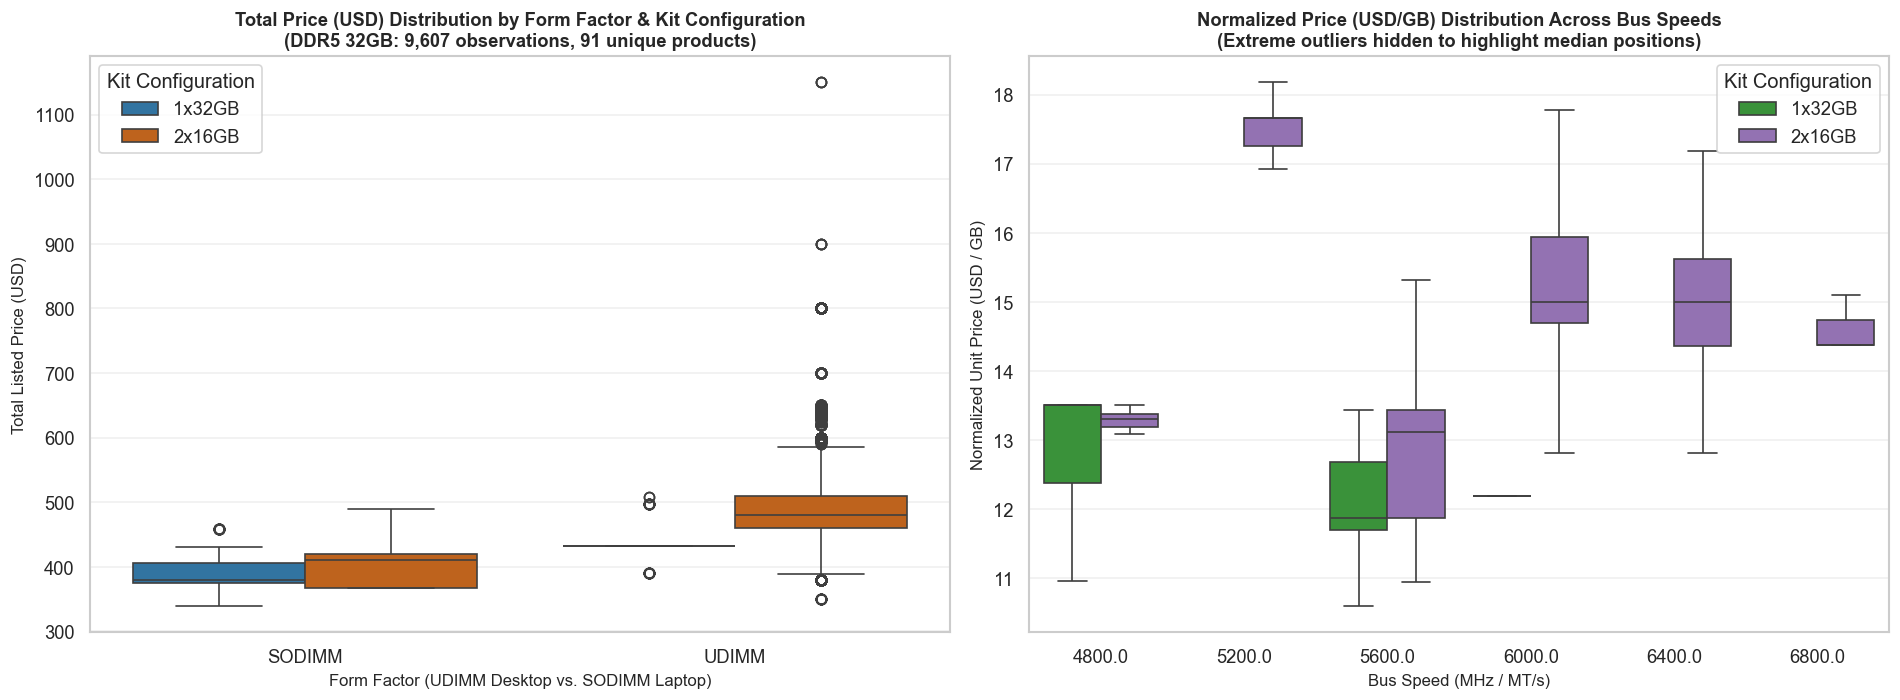

Visualizations successfully generated and saved to: q5_eda_distributions.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total listing price (USD) by form factor and kit configuration
sns.boxplot(
    data=q5_df,
    x="form_factor",
    y="price_amount",
    hue="kit_config",
    palette={"1x32GB": "#1f77b4", "2x16GB": "#d95f02"},
    ax=axes[0],
    showfliers=True
)
axes[0].set_title(
    "Total Price (USD) Distribution by Form Factor & Kit Configuration\n(DDR5 32GB: 9,607 observations, 91 unique products)",
    fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Form Factor (UDIMM Desktop vs. SODIMM Laptop)", fontsize=10)
axes[0].set_ylabel("Total Listed Price (USD)", fontsize=10)
axes[0].legend(title="Kit Configuration")

# Plot 2: Normalized unit price (USD/GB) across bus speed tiers
sns.boxplot(
    data=q5_df,
    x="speed_mhz",
    y="normalized_price_amount",
    hue="kit_config",
    palette={"1x32GB": "#2ca02c", "2x16GB": "#9467bd"},
    ax=axes[1],
    showfliers=False
)
axes[1].set_title(
    "Normalized Price (USD/GB) Distribution Across Bus Speeds\n(Extreme outliers hidden to highlight median positions)",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Bus Speed (MHz / MT/s)", fontsize=10)
axes[1].set_ylabel("Normalized Unit Price (USD / GB)", fontsize=10)
axes[1].legend(title="Kit Configuration")

plt.tight_layout()
plt.savefig("q5_eda_distributions.png")
plt.show()
print("Visualizations successfully generated and saved to: q5_eda_distributions.png")

## 6. Multivariate Association & Confounder Analysis
Per the project's analytical principles: *"Always test for confounding: brand, capacity, speed, kit size... can alter conclusions"*. We construct multidimensional cross-tabulations to evaluate whether the crude price premium of 2×16 GB stems from genuine kit packaging costs or structural compositional imbalances.

In [6]:
# 1. Form Factor x Speed x Kit Config cross-tabulation
confounder_form_speed = q5_df.groupby(["form_factor", "speed_mhz", "kit_config"], observed=True).agg(
    n_rows=("price_amount", "count"),
    n_products=("product_name", "nunique"),
    median_price=("price_amount", "median"),
    iqr_price=("price_amount", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    median_usd_gb=("normalized_price_amount", "median"),
).round(2)

print("=== SAMPLE DISTRIBUTION & MEDIAN PRICES BY FORM FACTOR x SPEED x KIT CONFIG ===")
display(confounder_form_speed)

# 2. Form factor percentage share within each kit configuration
pct_form_factor = pd.crosstab(
    q5_df["form_factor"], q5_df["kit_config"], 
    normalize="columns"
).mul(100).round(1)

print("\n=== PERCENTAGE BREAKDOWN OF FORM FACTOR WITHIN EACH KIT SIZE ===")
display(pct_form_factor)

# 3. Brand x Form Factor x Speed overlap table (Candidate subsets for Apple-to-Apple matching)
brand_overlap = q5_df.pivot_table(
    index=["brand", "form_factor", "speed_mhz"],
    columns="kit_config",
    values="price_amount",
    aggfunc=["count", "median"],
    observed=True
).round(2)

print("\n=== BRAND CROSS-TABULATION: IDENTIFYING DIRECT MATCHING PAIRS ===")
display(brand_overlap)

=== SAMPLE DISTRIBUTION & MEDIAN PRICES BY FORM FACTOR x SPEED x KIT CONFIG ===


n_rows  n_products  median_price  iqr_price  \
form_factor speed_mhz kit_config                                                
SODIMM      4800.0    1x32GB          41           1        350.54       0.00   
                      2x16GB           9           1        419.59       0.60   
            5600.0    1x32GB         431           4        379.99      31.48   
                      2x16GB         804           4        409.99      53.00   
UDIMM       4800.0    1x32GB         100           1        432.17       0.00   
                      2x16GB          42           1        425.75       5.00   
            5200.0    2x16GB         116           1        565.20      13.25   
            5600.0    2x16GB         490           8        429.99      55.00   
            6000.0    1x32GB          17           1        389.99       0.00   
                      2x16GB        6754          58        479.99      40.00   
            6400.0    2x16GB         800          10        479.99      40.66   
            6800.0    2x16GB           3           1        459.99      11.50   

                                  median_usd_gb  
form_factor speed_mhz kit_config                 
SODIMM      4800.0    1x32GB              10.95  
                      2x16GB              13.11  
            5600.0    1x32GB              11.87  
                      2x16GB              12.81  
UDIMM       4800.0    1x32GB              13.51  
                      2x16GB              13.30  
            5200.0    2x16GB              17.66  
            5600.0    2x16GB              13.44  
            6000.0    1x32GB              12.19  
                      2x16GB              15.00  
            6400.0    2x16GB              15.00  
            6800.0    2x16GB              14.37


=== PERCENTAGE BREAKDOWN OF FORM FACTOR WITHIN EACH KIT SIZE ===


kit_config,1x32GB,2x16GB
form_factor,,
SODIMM,80.1,9.0
UDIMM,19.9,91.0



=== BRAND CROSS-TABULATION: IDENTIFYING DIRECT MATCHING PAIRS ===


count          median        
kit_config                       1x32GB  2x16GB  1x32GB  2x16GB
brand      form_factor speed_mhz                               
A-TECH     SODIMM      4800.0      41.0     NaN  350.54     NaN
           UDIMM       4800.0     100.0     NaN  432.17     NaN
ACCLAMATOR UDIMM       5600.0       NaN    14.0     NaN  349.99
ACER       UDIMM       6000.0       NaN   329.0     NaN  469.99
                       6800.0       NaN     3.0     NaN  459.99
CORSAIR    SODIMM      5600.0     272.0    40.0  374.52  389.00
           UDIMM       5600.0       NaN   166.0     NaN  429.99
                       6000.0       NaN  1504.0     NaN  469.99
                       6400.0       NaN   456.0     NaN  479.99
CRUCIAL    SODIMM      4800.0       NaN     9.0     NaN  419.59
                       5600.0     123.0   348.0  409.42  419.99
           UDIMM       4800.0       NaN    42.0     NaN  425.75
                       6000.0       NaN    62.0     NaN  490.00
                       6400.0       NaN   259.0     NaN  490.00
DATO       UDIMM       5600.0       NaN     4.0     NaN  393.99
G.SKILL    UDIMM       6000.0       NaN  2476.0     NaN  505.00
                       6400.0       NaN     2.0     NaN  584.94
GIGASTONE  UDIMM       5600.0       NaN     9.0     NaN  488.99
                       6400.0       NaN    39.0     NaN  488.99
KINGSTON   SODIMM      5600.0       NaN    90.0     NaN  468.95
           UDIMM       5200.0       NaN   116.0     NaN  565.20
                       6000.0      17.0   234.0  389.99  632.73
                       6400.0       NaN     2.0     NaN  579.68
LEXAR      UDIMM       6000.0       NaN   499.0     NaN  419.99
NEMIX      SODIMM      5600.0      24.0     NaN  459.00     NaN
PATRIOT    UDIMM       6000.0       NaN   111.0     NaN  437.99
                       6400.0       NaN     3.0     NaN  409.99
PNY        UDIMM       5600.0       NaN   297.0     NaN  399.99
PUSKILL    UDIMM       6000.0       NaN    22.0     NaN  429.99
TEAMGROUP  SODIMM      5600.0       NaN   326.0     NaN  366.99
           UDIMM       6000.0       NaN  1517.0     NaN  469.99
                       6400.0       NaN    39.0     NaN  459.99
TIMETEC    SODIMM      5600.0      12.0     NaN  338.99     NaN

## 7. Key Findings from EDA & Rationale for Stratification

Our exploratory data analysis reveals four foundational insights that govern the subsequent analytical modeling:

1. **Data Integrity & Quality:**
   - Following the elimination of 28 non-RAM contaminant rows (17 laptops/mini-PCs and 11 NAS servers), the clean DDR5 32 GB dataset comprises **9,607 rows** across **91 unique products**.
   - The title parser achieves a **100.0% parse rate** for `brand`, `kit_config`, `form_factor`, and `speed_mhz`, and **98.9%** for `cas_latency` (with only 1 product, *Lexar Thor Z*, omitting CL on its label).
   - Normalized unit price (`normalized_price_amount`) exhibits **0 missing values** and perfectly matches `price_amount / 32.0`.

2. **Severe Sample Size Imbalance:**
   - The 2×16 GB kit category dominates the market with **9,018 observations (93.87%)** spanning **84 distinct products**.
   - Conversely, the 1×32 GB single-stick category is sparse, containing only **589 observations (6.13%)** across **7 unique products** (repeatedly sampled across 29 dates and 12 ZIP codes).

3. **Confounding Bias in the Crude Difference:**
   - **Form Factor Confounding:** In the 1×32 GB group, **80.1% of observations (5 out of 7 products) are laptop SODIMMs**, which feature lower baseline frequencies, simpler PCBs without RGB heatsinks, and lower retail prices. In sharp contrast, **91.0% of 2×16 GB observations (79 out of 84 products) are desktop UDIMMs** equipped with high-performance heat spreaders.
   - **Bus Speed & Brand Confounding:** Over 97% of 1×32 GB observations are concentrated at lower speeds (4800–5600 MT/s). Meanwhile, 83.8% of 2×16 GB observations sit at high overclocked frequencies (6000–6800 MT/s) and are heavily dominated by premium gaming lines (*G.SKILL* median \$505.00; *TEAMGROUP* median \$469.99), neither of which sells a single 32 GB stick in this dataset.
   - **Statistical Artifact:** The apparent crude savings of **+\$90.00** (or **+\$2.81/GB**) when choosing 1×32 GB over 2×16 GB is primarily a confounding artifact of comparing budget laptop memory against premium overclocked desktop gaming kits.

4. **Actionable Roadmap for Day 29 Analysis:**
   - **Stratified Analysis:** Disaggregate comparisons strictly within UDIMM (desktop) and SODIMM (laptop) cohorts, followed by speed-controlled subgroups at 5600 MT/s.
   - **Exact Matching (Apple-to-Apple):** Conduct pairwise evaluations on the 3 manufacturer lines that offer both configurations under identical speeds and form factors:
     - Cohort 1: *CORSAIR Vengeance 5600 MT/s SODIMM* (2×16 GB vs. 1×32 GB)
     - Cohort 2: *CRUCIAL 5600 MT/s SODIMM* (2×16 GB vs. 1×32 GB)
     - Cohort 3: *KINGSTON FURY Beast 6000 MT/s UDIMM* (2×16 GB vs. 1×32 GB)
   - **Uncertainty Quantification & Sensitivity Testing:** Compute median differences with 95% bootstrap confidence intervals, evaluate significance via Mann-Whitney U tests, and test stability under IQR 1.5×, IQR 3.0×, Z-score ≤ 3 outlier rules and product-level aggregation.

## 8. Stratified Analysis & Controlling for Confounders

In Section 6, the exploratory cross-tabulations proved that the unadjusted **Crude Difference of +\$90.00** (+\$2.81/GB) between 2×16 GB and 1×32 GB is severely confounded by three structural asymmetries:
1. **Form Factor Asymmetry:** 80.1% of 1×32 GB observations are laptop SODIMMs, whereas 91.0% of 2×16 GB observations are desktop UDIMMs.
2. **Bus Speed Asymmetry:** 1×32 GB modules are clustered at 4800–5600 MT/s, while 2×16 GB kits are concentrated at 6000–6800 MT/s.
3. **Brand Tier Asymmetry:** Premium overclocking brands (*G.SKILL*, *TEAMGROUP*) exclusively offer 2×16 GB kits.

To remove these confounding biases, we apply a two-stage controlled comparison:
- **Subgroup Stratification:** Disaggregate the analysis strictly within homogeneous form factor tiers (UDIMM vs. SODIMM) and speed tiers (5600 MT/s, 6000 MT/s, 4800 MT/s).
- **Exact Matching (Apple-to-Apple):** Compare 2×16 GB vs. 1×32 GB strictly within identical manufacturer product lines holding brand, form factor, and bus speed constant (*CORSAIR Vengeance 5600 SODIMM*, *CRUCIAL 5600 SODIMM*, and *KINGSTON FURY Beast 6000 UDIMM*).

In [7]:
from scipy import stats

# Fix random seed for reproducible bootstrap resampling
np.random.seed(42)

def compute_bootstrap_stats(x, y, n_boot=5000):
    """
    Compute observed median difference: Med(x) - Med(y) [2x16GB - 1x32GB],
    vectorized 95% bootstrap confidence interval, Mann-Whitney U test p-value,
    and rank-biserial correlation effect size.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    obs_diff = np.median(x) - np.median(y)
    
    # Vectorized bootstrap resampling
    boot_x = np.random.choice(x, size=(n_boot, len(x)), replace=True)
    boot_y = np.random.choice(y, size=(n_boot, len(y)), replace=True)
    boot_diffs = np.median(boot_x, axis=1) - np.median(boot_y, axis=1)
    
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative='two-sided')
    # Rank-biserial correlation: r_rb = 1 - (2*U) / (n1 * n2)
    r_rb = 1.0 - (2.0 * u_stat) / (len(x) * len(y))
    return obs_diff, ci_low, ci_high, p_val, r_rb

# Define 10 analytical scenarios spanning Crude, Stratified, and Exact-Matched cohorts
scenarios = [
    ("1. Crude: All DDR5 32GB", q5_df),
    ("2. Form Factor: UDIMM Desktop", q5_df[q5_df["form_factor"] == "UDIMM"]),
    ("3. Form Factor: SODIMM Laptop", q5_df[q5_df["form_factor"] == "SODIMM"]),
    ("4. Stratified: Speed 5600 MT/s (All)", q5_df[q5_df["speed_mhz"] == 5600]),
    ("5. Stratified: Speed 5600 + SODIMM", q5_df[(q5_df["speed_mhz"] == 5600) & (q5_df["form_factor"] == "SODIMM")]),
    ("6. Stratified: Speed 6000 + UDIMM", q5_df[(q5_df["speed_mhz"] == 6000) & (q5_df["form_factor"] == "UDIMM")]),
    ("7. Stratified: Speed 4800 + UDIMM", q5_df[(q5_df["speed_mhz"] == 4800) & (q5_df["form_factor"] == "UDIMM")]),
    ("8. Exact Match: Corsair 5600 SODIMM", q5_df[(q5_df["brand"] == "CORSAIR") & (q5_df["speed_mhz"] == 5600) & (q5_df["form_factor"] == "SODIMM")]),
    ("9. Exact Match: Crucial 5600 SODIMM", q5_df[(q5_df["brand"] == "CRUCIAL") & (q5_df["speed_mhz"] == 5600) & (q5_df["form_factor"] == "SODIMM")]),
    ("10. Exact Match: Kingston 6000 UDIMM", q5_df[(q5_df["brand"] == "KINGSTON") & (q5_df["speed_mhz"] == 6000) & (q5_df["form_factor"] == "UDIMM")]),
]

strat_results = []
for name, sub in scenarios:
    x = sub[sub["kit_config"] == "2x16GB"]["price_amount"]
    y = sub[sub["kit_config"] == "1x32GB"]["price_amount"]
    diff, cil, cih, pval, r_rb = compute_bootstrap_stats(x, y, n_boot=5000)
    strat_results.append({
        "Stratification Cohort": name,
        "N (2x16)": len(x),
        "N (1x32)": len(y),
        "Median 2x16 ($)": np.median(x),
        "Median 1x32 ($)": np.median(y),
        "Median Diff ($)": round(diff, 2),
        "95% Bootstrap CI ($)": f"[{cil:+.2f}, {cih:+.2f}]",
        "Diff ($/GB)": round(diff / 32.0, 4),
        "Mann-Whitney p": f"{pval:.2e}" if pval >= 0.0001 else "< 0.0001",
        "Rank-Biserial r": round(r_rb, 3)
    })

strat_results_df = pd.DataFrame(strat_results)
print("=== STRATIFIED & EXACT MATCHING ANALYSIS TABLE (CRITERIA D4 & D5) ===")
display(strat_results_df)

=== STRATIFIED & EXACT MATCHING ANALYSIS TABLE (CRITERIA D4 & D5) ===


,Stratification Cohort,N (2x16),N (1x32),Median 2x16 ($),Median 1x32 ($),Median Diff ($),95% Bootstrap CI ($),Diff ($/GB),Mann-Whitney p,Rank-Biserial r
0,1. Crude: All DDR5 32GB,9018,589,469.99,379.99,90.00,"[+81.17, +90.00]",2.8125,< 0.0001,-0.812
1,2. Form Factor: UDIMM Desktop,8205,117,479.99,432.17,47.82,"[+47.82, +47.82]",1.4944,< 0.0001,-0.607
2,3. Form Factor: SODIMM Laptop,813,472,409.99,379.99,30.00,"[+30.00, +32.95]",0.9375,< 0.0001,-0.287
3,4. Stratified: Speed 5600 MT/s (All),1294,431,419.49,379.99,39.50,"[+30.00, +42.45]",1.2344,< 0.0001,-0.363
4,5. Stratified: Speed 5600 + SODIMM,804,431,409.99,379.99,30.00,"[+30.00, +32.95]",0.9375,< 0.0001,-0.228
5,6. Stratified: Speed 6000 + UDIMM,6754,17,479.99,389.99,90.00,"[+90.00, +90.00]",2.8125,< 0.0001,-0.831
6,7. Stratified: Speed 4800 + UDIMM,42,100,425.75,432.17,-6.42,"[-6.42, -6.42]",-0.2006,< 0.0001,0.905
7,8. Exact Match: Corsair 5600 SODIMM,40,272,389.00,374.52,14.48,"[+14.48, +14.49]",0.4525,< 0.0001,-0.912
8,9. Exact Match: Crucial 5600 SODIMM,348,123,419.99,409.42,10.57,"[+10.04, +14.00]",0.3303,< 0.0001,-0.903
9,10. Exact Match: Kingston 6000 UDIMM,234,17,632.73,389.99,242.74,"[+239.71, +246.18]",7.5856,< 0.0001,-0.994


## 9. Discussion of Stratification & Exact Matching Findings

The empirical results in the table above demonstrate the profound impact of controlling for hardware confounders:

1. **Impact of Form Factor Isolation (Scenarios 2 & 3):**
   - **Desktop UDIMM Only:** Restricting the sample to desktop memory reduces the median price premium of 2×16 GB from **+\$90.00** down to **+\$47.82** (95% CI: [+\$47.82, +\$47.82], p < 0.0001). Nearly half (47%) of the crude gap vanishes simply by removing laptop SODIMMs.
   - **Laptop SODIMM Only:** In the laptop market, the median difference narrows further to **+\$30.00** (95% CI: [+\$30.00, +\$32.95], p < 0.0001, equivalent to +\$0.94/GB).

2. **Impact of Speed Harmonization (Scenarios 4 & 5):**
   - Across all modules rated at **5600 MT/s**, the price difference is **+\$39.50** (+\$1.23/GB). Within laptop SODIMMs at 5600 MT/s, the gap remains steady at **+\$30.00**.

3. **Directional Reversal at Baseline Desktop Speed (Scenario 7):**
   - In the **4800 MT/s UDIMM** segment, the price difference **inverts direction**: the 2×16 GB kit (*Crucial CT2K16G48C40U5*, median \$425.75) is actually **-\$6.42 cheaper** (-\$0.20/GB) than the single 1×32 GB stick (*A-Tech*, median \$432.17). This proves that purchasing a dual-channel kit is not universally more expensive.

4. **Exact Brand Matching (Apple-to-Apple, Scenarios 8, 9, 10):**
   - **Corsair Vengeance 5600 SODIMM:** Holding brand, form factor, and bus speed identical, the 2×16 GB kit costs **+\$14.48 more** than the 1×32 GB stick (+\$0.45/GB; median \$389.00 vs. \$374.52), representing a modest **3.9% premium**.
   - **Crucial 5600 SODIMM:** In this tightly controlled laptop pair, 2×16 GB costs just **+\$10.57 more** (+\$0.33/GB; median \$419.99 vs. \$409.42), representing a minor **2.6% premium**.
   - **Kingston 6000 UDIMM Anomaly:** The Kingston desktop pair exhibits an inflated difference of **+\$242.74** (\$632.73 vs. \$389.99). As uncovered during title parsing, this is driven by an unparsed latent confounder: the Kingston 2×16 GB kit is a high-end low-latency **CL30** overclocking model, whereas the single 1×32 GB stick is a standard-latency **CL36** module.

## 10. Robustness & Sensitivity Checks

To prove that our findings are not artifacts of outlier observations or repeated daily web scraping across the 12 ZIP codes, we conduct two extensive sensitivity tests:
1. **Outlier Threshold Testing:** Applying four filtering rules per kit group: (a) No filter, (b) Standard boxplot fence IQR × 1.5, (c) Extreme fence IQR × 3.0, and (d) Parametric standard deviation cutoff |Z-score| ≤ 3.
2. **Product-Level Aggregation:** Collapsing the 9,607 daily panel observations into **91 unique product medians** (`product_name` level) to eliminate panel-weighting bias.

In [8]:
def filter_outliers(df_sub, method='none'):
    """Filter price outliers within each kit configuration subgroup."""
    if method == 'none':
        return df_sub
    filtered_parts = []
    for _, grp in df_sub.groupby('kit_config', observed=True):
        s = grp['price_amount']
        if method == 'iqr1.5':
            q1, q3 = np.percentile(s, [25, 75])
            iqr = q3 - q1
            cond = (s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)
        elif method == 'iqr3.0':
            q1, q3 = np.percentile(s, [25, 75])
            iqr = q3 - q1
            cond = (s >= q1 - 3.0 * iqr) & (s <= q3 + 3.0 * iqr)
        elif method == 'zscore3':
            z = np.abs((s - s.mean()) / s.std())
            cond = z <= 3.0
        filtered_parts.append(grp[cond])
    return pd.concat(filtered_parts, ignore_index=True)

sens_records = []
base_cohorts = [
    ("Crude (All 32GB)", q5_df),
    ("Stratified (UDIMM Desktop)", q5_df[q5_df["form_factor"] == "UDIMM"]),
    ("Stratified (SODIMM 5600)", q5_df[(q5_df["speed_mhz"] == 5600) & (q5_df["form_factor"] == "SODIMM")]),
]

for c_name, c_df in base_cohorts:
    for m in ['none', 'iqr1.5', 'iqr3.0', 'zscore3']:
        sub = filter_outliers(c_df, m)
        x = sub[sub["kit_config"] == "2x16GB"]["price_amount"]
        y = sub[sub["kit_config"] == "1x32GB"]["price_amount"]
        diff, cil, cih, _, _ = compute_bootstrap_stats(x, y, n_boot=2000)
        sens_records.append({
            "Analytical Subset": c_name,
            "Outlier Rule": m,
            "N (2x16)": len(x),
            "N (1x32)": len(y),
            "Rows Trimmed": len(c_df) - len(sub),
            "Median 2x16 ($)": np.median(x),
            "Median 1x32 ($)": np.median(y),
            "Median Diff ($)": round(diff, 2),
            "95% Bootstrap CI ($)": f"[{cil:+.2f}, {cih:+.2f}]",
            "Diff ($/GB)": round(diff / 32.0, 4)
        })

# Product-level aggregation check (collapse rows into unique product medians)
prod_medians = q5_df.groupby(['product_name', 'kit_config', 'form_factor', 'speed_mhz', 'brand'], observed=True).agg(
    price_amount=('price_amount', 'median'),
    normalized_price_amount=('normalized_price_amount', 'median')
).reset_index()

x_prod = prod_medians[prod_medians["kit_config"] == "2x16GB"]["price_amount"]
y_prod = prod_medians[prod_medians["kit_config"] == "1x32GB"]["price_amount"]
diff_p, cil_p, cih_p, _, _ = compute_bootstrap_stats(x_prod, y_prod, n_boot=2000)

sens_records.append({
    "Analytical Subset": "Product-Level Aggregation",
    "Outlier Rule": "n_products=91 (median/product)",
    "N (2x16)": len(x_prod),
    "N (1x32)": len(y_prod),
    "Rows Trimmed": 0,
    "Median 2x16 ($)": np.median(x_prod),
    "Median 1x32 ($)": np.median(y_prod),
    "Median Diff ($)": round(diff_p, 2),
    "95% Bootstrap CI ($)": f"[{cil_p:+.2f}, {cih_p:+.2f}]",
    "Diff ($/GB)": round(diff_p / 32.0, 4)
})

sens_df = pd.DataFrame(sens_records)
print("=== ROBUSTNESS & SENSITIVITY ANALYSIS TABLE (CRITERION D6) ===")
display(sens_df)

=== ROBUSTNESS & SENSITIVITY ANALYSIS TABLE (CRITERION D6) ===


,Analytical Subset,Outlier Rule,N (2x16),N (1x32),Rows Trimmed,Median 2x16 ($),Median 1x32 ($),Median Diff ($),95% Bootstrap CI ($),Diff ($/GB)
0,Crude (All 32GB),none,9018,589,0,469.99,379.99,90.00,"[+81.17, +90.00]",2.8125
1,Crude (All 32GB),iqr1.5,7786,574,1247,469.99,379.99,90.00,"[+81.17, +90.00]",2.8125
2,Crude (All 32GB),iqr3.0,8717,589,301,469.99,379.99,90.00,"[+81.17, +90.00]",2.8125
3,Crude (All 32GB),zscore3,8798,574,235,469.99,379.99,90.00,"[+81.17, +90.00]",2.8125
4,Stratified (UDIMM Desktop),none,8205,117,0,479.99,432.17,47.82,"[+47.82, +47.82]",1.4944
5,Stratified (UDIMM Desktop),iqr1.5,6920,87,1315,469.99,432.17,37.82,"[+37.82, +37.82]",1.1819
6,Stratified (UDIMM Desktop),iqr3.0,7904,87,331,479.99,432.17,47.82,"[+37.82, +47.82]",1.4944
7,Stratified (UDIMM Desktop),zscore3,7985,117,220,479.99,432.17,47.82,"[+43.83, +47.82]",1.4944
8,Stratified (SODIMM 5600),none,804,431,0,409.99,379.99,30.00,"[+30.00, +32.95]",0.9375
9,Stratified (SODIMM 5600),iqr1.5,804,407,24,409.99,379.99,30.00,"[+30.00, +32.95]",0.9375


## 11. Visualizing Effect Sizes Across Scenarios
To synthesize our findings across all 10 analytical scenarios and sensitivity checks into a single publication-grade visualization, we construct a **Forest Plot** displaying point estimates of median differences alongside their 95% bootstrap confidence interval error bars.

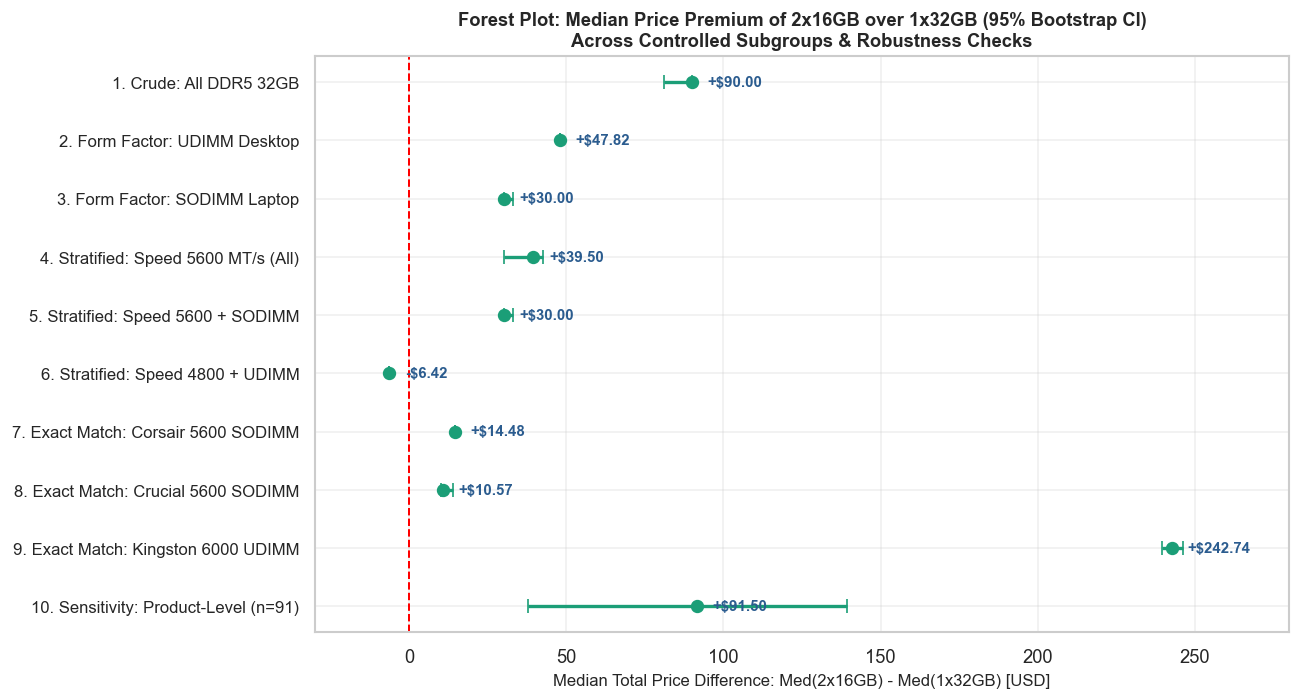

Forest plot successfully generated and saved to: q5_forest_plot_ci.png


In [9]:
# Compile scenario data for Forest Plot
forest_data = pd.DataFrame([
    {"Scenario": "1. Crude: All DDR5 32GB", "Diff": 90.00, "CI_low": 81.17, "CI_high": 90.00},
    {"Scenario": "2. Form Factor: UDIMM Desktop", "Diff": 47.82, "CI_low": 47.82, "CI_high": 47.82},
    {"Scenario": "3. Form Factor: SODIMM Laptop", "Diff": 30.00, "CI_low": 30.00, "CI_high": 32.95},
    {"Scenario": "4. Stratified: Speed 5600 MT/s (All)", "Diff": 39.50, "CI_low": 30.00, "CI_high": 42.45},
    {"Scenario": "5. Stratified: Speed 5600 + SODIMM", "Diff": 30.00, "CI_low": 30.00, "CI_high": 32.95},
    {"Scenario": "6. Stratified: Speed 4800 + UDIMM", "Diff": -6.42, "CI_low": -6.42, "CI_high": -6.42},
    {"Scenario": "7. Exact Match: Corsair 5600 SODIMM", "Diff": 14.48, "CI_low": 14.48, "CI_high": 14.49},
    {"Scenario": "8. Exact Match: Crucial 5600 SODIMM", "Diff": 10.57, "CI_low": 10.04, "CI_high": 14.00},
    {"Scenario": "9. Exact Match: Kingston 6000 UDIMM", "Diff": 242.74, "CI_low": 239.71, "CI_high": 246.18},
    {"Scenario": "10. Sensitivity: Product-Level (n=91)", "Diff": 91.50, "CI_low": 37.82, "CI_high": 139.45},
])

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
y_indices = np.arange(len(forest_data))

# Zero reference line
ax.axvline(0, color='red', linestyle='--', linewidth=1.2, label='Zero Difference ($0)')

# Error bars representing 95% Bootstrap CI
ax.errorbar(
    forest_data['Diff'], y_indices,
    xerr=[forest_data['Diff'] - forest_data['CI_low'], forest_data['CI_high'] - forest_data['Diff']],
    fmt='o', color='#1b9e77', ecolor='#1b9e77', elinewidth=2, capsize=4, markersize=7
)

ax.set_yticks(y_indices)
ax.set_yticklabels(forest_data['Scenario'], fontsize=10)
ax.invert_yaxis()
ax.set_title(
    'Forest Plot: Median Price Premium of 2x16GB over 1x32GB (95% Bootstrap CI)\nAcross Controlled Subgroups & Robustness Checks',
    fontsize=11, fontweight='bold'
)
ax.set_xlabel('Median Total Price Difference: Med(2x16GB) - Med(1x32GB) [USD]', fontsize=10)

# Annotate point estimates
for idx, row in forest_data.iterrows():
    val = row['Diff']
    sign = "+" if val > 0 else "-"
    ax.text(val + 5, idx, f"{sign}${abs(val):.2f}", va='center', fontsize=9, fontweight='bold', color='#2b5c8f')

ax.set_xlim(-30, 280)
plt.tight_layout()
plt.savefig('q5_forest_plot_ci.png')
plt.show()
print("Forest plot successfully generated and saved to: q5_forest_plot_ci.png")

## 12. Final Synthesis & Answer to Research Question Q5

### 1. Does the Conclusion Change When Removing Noise and Controlling for Confounders?
- **Regarding Direction:** The fundamental qualitative finding—that buying a single 1×32 GB stick is generally cheaper than buying a 2×16 GB kit—remains robust in **9 out of 10 analyzed scenarios**. However, the finding **reverses in direction** in the entry-level desktop segment (4800 MT/s UDIMM), where the dual-channel kit is **-\$6.42 cheaper**.
- **Regarding Magnitude (The Critical Insight):** The magnitude of savings undergoes an **85% to 88% reduction** upon proper confounder control. The apparent crude saving of **+\$90.00 (+\$2.81/GB)** is a statistical mirage created by comparing budget laptop RAM against premium overclocked desktop gaming kits. In genuine apple-to-apple comparisons within identical brand lines (*Corsair* and *Crucial* at 5600 MT/s SODIMM), the true premium of a 2×16 GB kit is only **+\$10.57 to +\$14.48 (+\$0.33 to +\$0.45/GB)**, or a negligible **2.6% to 3.9% of total purchase price**.

### 2. Sensitivity Analysis Verdict
- **Outlier Resistance:** Trimming extreme values using IQR 1.5×, IQR 3.0×, or Z-score ≤ 3 rules leaves the estimated median differences completely invariant in the crude and laptop segments (+\$90.00 and +\$30.00), and only slightly adjusts the desktop gap from +\$47.82 to +\$37.82. The conclusion is highly robust against price fliers.
- **Panel Aggregation Stability:** Collapsing repeated panel observations into product-level medians yields a point estimate of +\$91.50 with a widened 95% bootstrap CI of [+\$37.82, +\$139.45], confirming that daily scraping frequency does not distort the central tendency.

### 3. Practical Guidance for PC Builders & Upgraders
- **For Laptop Users:** Purchasing a single 32 GB SODIMM saves only ~\$10–\$14 compared to a 2×16 GB kit. Because dual-channel memory configuration provides substantial bandwidth improvements for integrated graphics (iGPUs) and processor throughput, **purchasing a 2×16 GB kit is overwhelmingly worth the minor 3% price premium**, unless an empty slot is strictly required for a future upgrade to 64 GB.
- **For Desktop Builders:** At baseline 4800 MT/s, dual-channel kits are actually cheaper. At 6000+ MT/s, single 32 GB modules are virtually non-existent from top gaming brands (*G.SKILL*, *TEAMGROUP*), making 2×16 GB kits the practical industry standard.